# Compare with permaFoam Simulation Result

In [1]:
import sys
sys.path.append('../../')

from utils import parse_permafoam_output
from utils.plotting_utils import make_comparison_figure, make_resolution_figure
from plotting_utils import make_comparison_figure, make_resolution_figure
import pickle as pkl
import jax.numpy as jnp
import os.path

In [2]:
permaFoam_folder = "../../output/synthetic_case/permaFoam/"
permaFoam_filename = "permaFoam_output.pkl"

save_folder = "../../output/synthetic_case/"
save_file = f"cryorich_AD_output.pkl"

fields = ("T", "psi", "thetal", "thetag", "theta")

save_plots_folder = "../../figures/supplementary/"
save_plots_file = "comparison_permaFoam.png"

#### If not yet done, parse permaFoam output to .pkl file

In [3]:
if os.path.isfile(permaFoam_folder + permaFoam_filename):
    print(f"File {permaFoam_folder + permaFoam_filename} already exists, skipping parsing.")
else: 
    parse_permafoam_output(case_dir=permaFoam_folder, out_file=permaFoam_folder + permaFoam_filename,
                           fields=fields, xtot=10,
                           x_patch="top", z_patch="downSlope", verbose=True)
    

File ../../output/synthetic_case/permaFoam/permaFoam_output.pkl already exists, skipping parsing.


#### Open both simulation outputs

In [4]:
import jax; jax.config.update('jax_enable_x64', True)   # before pkl.load

with open(save_folder+save_file, 'rb') as pickle_file:
    data = pkl.load(pickle_file)
    X = data['X']
    Z = data['Z']
    theta_l_cr = data['theta_l_total']
    theta_i_cr = data['theta_i_total']
    T_cr = data['T_total']
    time = data['time_array']
    q_runoff = data['q_runoff']
    q_inf_interp = data['q_inf_interp']
    q_x_array = data['qx_array']
    q_z_array = data['qz_array']

N_x = X.shape[1]
N_z = X.shape[0]
N_tot = N_x * N_z
dx = X[0, 1] - X[0, 0]
dz = Z[1, 0] - Z[0, 0]
print(f"dx = {dx}, dz = {dz}, N_x = {N_x}, N_z = {N_z}, N_tot = {N_tot}")

with open(permaFoam_folder + permaFoam_filename, 'rb') as pickle_file:
    data = pkl.load(pickle_file)
    t_permaFoam = data['times']
    X_permaFoam = data['X']
    Z_permaFoam = data['Z']
    theta_l_pf = []
    theta_i_pf = []
    T_pf = []
    for field in data['fields'].keys():
        theta_l_pf.append(data['fields'][field]['thetal'])
        theta_i_pf.append(data['fields'][field]['thetag'])
        T_pf.append(data['fields'][field]['T']-273.15)  # convert to °C
    


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


dx = 0.20000000000000004, dz = 0.004999999999999999, N_x = 50, N_z = 200, N_tot = 10000


#### Plot and save figure

max abs theta_l diff: 0.037
max abs theta_i diff: 0.013
max abs T diff: 0.043


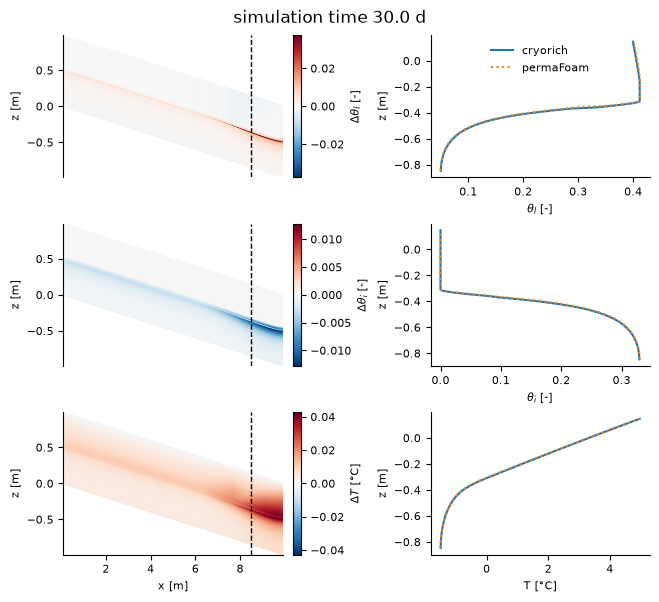

In [5]:
fig, ax = make_comparison_figure(X,Z,theta_l_cr, theta_i_cr, T_cr, theta_l_pf, theta_i_pf, T_pf, time, time_index=-1,cmap = 'RdBu_r',x_cut=8.5)
fig.savefig(save_plots_folder+save_plots_file, dpi=600, bbox_inches='tight')

# Mass-balance check 

In [6]:
def mass_balance_check(q_runoff, q_x_array, theta_i,theta_l, t, N_tot, dx, dz):
    """
    Check mass balance of the system.
    """
    dx_tilde = jnp.sqrt(dx**2 + dz**2) 
    flux_balance = []
    mass_balance = []
    total_inflow = []
    total_outflow = []
    total_storage_change = []
    # Calculate the total inflow and outflow
    for t_i in range(1,len(t)):
        q_x = q_x_array[t_i]  # Assuming q_x is the last element in the x-direction
        total_inflow.append(0)
        total_outflow.append(jnp.sum(q_runoff[t_i])*dx_tilde + jnp.sum(q_x[:, -1])*dz)
        total_storage_change.append((jnp.sum(theta_l[t_i] + theta_i[t_i])*dx*dz - jnp.sum(theta_l[t_i-1] + theta_i[t_i-1])*dx*dz)/(t[t_i] - t[t_i-1]))
        flux_balance.append(total_inflow[-1] - total_outflow[-1] - total_storage_change[-1])
        mass_balance.append((flux_balance[-1])*(t[t_i] - t[t_i-1])/(N_tot*dx*dz))
    
    return flux_balance, mass_balance, total_inflow, total_outflow, total_storage_change

#### Open output with absolute tolerance of 1e-4

In [7]:
with open(save_folder+"cryorich_AD_output_atol1e-4.pkl", 'rb') as pickle_file:
    data = pkl.load(pickle_file)
    X_mb = data['X']
    Z_mb = data['Z']
    theta_l_mb = data['theta_l_total']
    theta_i_mb = data['theta_i_total']
    T_mb = data['T_total']
    time_mb = data['time_array']
    q_runoff_mb = data['q_runoff']
    q_inf_interp_mb = data['q_inf_interp']
    q_x_array_mb = data['qx_array']
    q_z_array_mb = data['qz_array']

N_x = X_mb.shape[1]
N_z = X_mb.shape[0]
N_tot = N_x * N_z
dx = X_mb[0, 1] - X_mb[0, 0]
dz = Z_mb[1, 0] - Z_mb[0, 0]
print(f"dx = {dx}, dz = {dz}, N_x = {N_x}, N_z = {N_z}, N_tot = {N_tot}")

dx = 0.20000000000000004, dz = 0.004999999999999999, N_x = 50, N_z = 200, N_tot = 10000


#### Calculate relative error in storage 

In [8]:
flux_balance, mass_balance, total_inflow, total_outflow, total_storage_change = mass_balance_check(q_runoff_mb, q_x_array_mb, theta_i_mb, theta_l_mb, time_mb, N_tot, dx, dz)
cum_error = jnp.sum(abs(jnp.array(mass_balance))) * N_tot*dx*dz
W_end = jnp.sum(theta_l_mb[-1] + theta_i_mb[-1]) * dx*dz
rel_error_storage = cum_error / W_end
print(f"Relative error in storage: {rel_error_storage}")

Relative error in storage: 7.058089598823631e-05


#### Open output with absolute tolerance of 1e-8

In [9]:
with open(save_folder+"cryorich_AD_output_atol1e-8.pkl", 'rb') as pickle_file:
    data = pkl.load(pickle_file)
    X_mb = data['X']
    Z_mb = data['Z']
    theta_l_mb = data['theta_l_total']
    theta_i_mb = data['theta_i_total']
    T_mb = data['T_total']
    time_mb = data['time_array']
    q_runoff_mb = data['q_runoff']
    q_inf_interp_mb = data['q_inf_interp']
    q_x_array_mb = data['qx_array']
    q_z_array_mb = data['qz_array']

N_x = X_mb.shape[1]
N_z = X_mb.shape[0]
N_tot = N_x * N_z
dx = X_mb[0, 1] - X_mb[0, 0]
dz = Z_mb[1, 0] - Z_mb[0, 0]
print(f"dx = {dx}, dz = {dz}, N_x = {N_x}, N_z = {N_z}, N_tot = {N_tot}")

dx = 0.20000000000000004, dz = 0.004999999999999999, N_x = 50, N_z = 200, N_tot = 10000


#### Calculate relative error in storage 

In [10]:
flux_balance, mass_balance, total_inflow, total_outflow, total_storage_change = mass_balance_check(q_runoff_mb, q_x_array_mb, theta_i_mb, theta_l_mb, time_mb, N_tot, dx, dz)
cum_error = jnp.sum(abs(jnp.array(mass_balance))) * N_tot*dx*dz
W_end = jnp.sum(theta_l_mb[-1] + theta_i_mb[-1]) * dx*dz
rel_error_storage = cum_error / W_end
print(f"Relative error in storage: {rel_error_storage}")

Relative error in storage: 2.9736950524971053e-07
